# Exploratory Data Analysis

## Objective

This notebook documents an exploratory analysis of the prepared UCI Heart Disease dataset. The data combines Cleveland, Hungarian, Switzerland, and VA observations; the binary target is `0` for no heart disease and `1` for heart disease.

The analysis reviews dataset structure and quality, summarizes feature distributions, examines selected relationships with the target, and records correlation patterns. Figures are saved to `screenshots/` for inclusion in the academic report. This is descriptive analysis, not evidence of causal effects or clinical suitability. No missing values are imputed and no rows are removed here; those decisions belong to a documented training pipeline.

## Imports and plotting configuration

Import the analysis and visualization libraries used throughout the notebook. A consistent seaborn theme and readable Matplotlib defaults make the tables and saved figures suitable for review and report screenshots.

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold"})

candidate_roots = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (path for path in candidate_roots if (path / "data" / "raw" / "heart.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate data/raw/heart.csv from the current directory "
        f"({Path.cwd()}) or its parent directories."
    )

dataset_path = project_root / "data" / "raw" / "heart.csv"
figures_dir = project_root / "screenshots"
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Dataset: {dataset_path}")
print(f"Figures will be saved to: {figures_dir}")

Dataset: c:\Users\kshvj\OneDrive\Documents\LJ's creations\MTECH\Git projects\heart-disease-pipeline-mlops-bits-assignment\data\raw\heart.csv
Figures will be saved to: c:\Users\kshvj\OneDrive\Documents\LJ's creations\MTECH\Git projects\heart-disease-pipeline-mlops-bits-assignment\screenshots


## Dataset Loading

Load the prepared CSV using the repository-relative equivalent of `../data/raw/heart.csv`. The path discovery above supports running all cells from either the repository root or the `notebooks/` directory. Display the dimensions, first records, and a reproducible random sample (fixed seed) to verify the artifact and inspect representative rows.

In [20]:
df = pd.read_csv(dataset_path)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())
display(df.sample(n=min(5, len(df)), random_state=42))

Dataset shape: 920 rows × 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
319,36.0,1.0,2.0,120.0,166.0,0.0,0.0,180.0,0.0,0.0,NaN,NaN,NaN,0
377,45.0,1.0,2.0,140.0,224.0,1.0,0.0,122.0,0.0,0.0,NaN,NaN,NaN,0
538,48.0,1.0,4.0,160.0,329.0,0.0,0.0,92.0,1.0,1.5,2.0,NaN,NaN,1
296,59.0,1.0,4.0,164.0,176.0,1.0,2.0,90.0,0.0,1.0,2.0,2.0,6.0,1
531,40.0,0.0,4.0,150.0,392.0,0.0,0.0,130.0,0.0,2.0,2.0,NaN,6.0,1


## Dataset Overview

Review the schema and in-memory footprint before interpreting individual features. `info()` provides non-null counts and inferred types; the explicit type and memory tables make these details easy to compare and capture in project documentation. The prepared schema is expected to contain 13 predictors and the binary `target` column.

In [21]:
print(f"Shape: {df.shape}")
print("Columns:")
display(pd.DataFrame({"column": df.columns}))
print("Data types:")
display(df.dtypes.rename("dtype").to_frame())
print("Dataframe info:")
df.info()
memory_usage = df.memory_usage(deep=True)
print(f"Total memory usage: {memory_usage.sum():,} bytes ({memory_usage.sum() / 1024:.2f} KiB)")
display(memory_usage.rename("memory_bytes").to_frame())

Shape: (920, 14)
Columns:


,column
0,age
1,sex
2,cp
3,trestbps
4,chol
5,fbs
6,restecg
7,thalach
8,exang
9,oldpeak


Data types:


,dtype
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  861 non-null    float64
 4   chol      890 non-null    float64
 5   fbs       830 non-null    float64
 6   restecg   918 non-null    float64
 7   thalach   865 non-null    float64
 8   exang     865 non-null    float64
 9   oldpeak   858 non-null    float64
 10  slope     611 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
 13  target    920 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 100.8 KB
Total memory usage: 103,172 bytes (100.75 KiB)


,memory_bytes
Index,132
age,7360
sex,7360
cp,7360
trestbps,7360
chol,7360
fbs,7360
restecg,7360
thalach,7360
exang,7360


**Interpretation.** A compact, tabular schema makes this dataset practical for local iteration and reproducible training. Numeric storage does not imply that every feature is continuous: variables such as sex, chest-pain type, exercise-induced angina, and target are categorical codes. Treat them accordingly in visualizations and downstream preprocessing.

## Data Quality Assessment

Quantify missingness by feature and as a percentage of all records, count exact duplicate rows, and inspect type consistency. Missing values are expected because the source datasets use `?` for unknown measurements, particularly for some diagnostic fields. This notebook reports, but does not impute or drop, those observations. The type check also flags nonnumeric values in columns expected to be numeric and confirms that observed target values belong to `{0, 1}`.

In [22]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100),
}).sort_values("missing_count", ascending=False)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Total missing cells: {df.isna().sum().sum():,}")
display(missing_summary.style.format({"missing_percent": "{:.2f}%"}))

non_numeric_columns = df.select_dtypes(exclude=[np.number]).columns.tolist()
expected_target_values = {0, 1}
observed_target_values = set(df["target"].dropna().unique()) if "target" in df else set()
print(f"Non-numeric columns: {non_numeric_columns or 'None'}")
print(f"Observed target values: {sorted(observed_target_values)}")
if non_numeric_columns:
    print("Review non-numeric columns before numerical modeling.")
if observed_target_values - expected_target_values:
    raise ValueError(f"Unexpected target values: {observed_target_values - expected_target_values}")
if "target" not in df:
    raise KeyError("Required target column is missing.")

Exact duplicate rows: 2
Total missing cells: 1,759


,missing_count,missing_percent
ca,611,66.41%
thal,486,52.83%
slope,309,33.59%
fbs,90,9.78%
oldpeak,62,6.74%
trestbps,59,6.41%
thalach,55,5.98%
exang,55,5.98%
chol,30,3.26%
restecg,2,0.22%


Non-numeric columns: None
Observed target values: [np.int64(0), np.int64(1)]


**Observations.** Missingness is concentrated in a subset of clinical measurements rather than distributed uniformly. The count and percentage table identifies columns that may require careful handling. Duplicate rows are reported but retained to preserve source records. Numeric source columns should be checked for valid ranges and categorical codes; an integer or floating-point dtype alone is not a data-quality guarantee.

## Statistical Summary

Use `describe()` to summarize numeric columns. The table reports non-missing counts and common distribution statistics; differences between `count` and the dataset row count reflect missing observations. Pay particular attention to age, serum cholesterol, resting blood pressure, and maximum heart rate, while remembering that merged cohorts may differ in measurement completeness and composition.

In [23]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,920.0,53.510870,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920.0,0.789130,0.408148,0.0,1.0,1.0,1.0,1.0
cp,920.0,3.250000,0.930969,1.0,3.0,4.0,4.0,4.0
trestbps,861.0,132.132404,19.066070,0.0,120.0,130.0,140.0,200.0
chol,890.0,199.130337,110.780810,0.0,175.0,223.0,268.0,603.0
fbs,830.0,0.166265,0.372543,0.0,0.0,0.0,0.0,1.0
restecg,918.0,0.604575,0.805827,0.0,0.0,0.0,1.0,2.0
thalach,865.0,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0
exang,865.0,0.389595,0.487941,0.0,0.0,0.0,1.0,1.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.0,0.5,1.5,6.2


**Interpretation guide.** Age describes the cohort's age range and central tendency. Cholesterol (`chol`) and resting blood pressure (`trestbps`) have missing measurements, so their reported counts may be lower than the total number of records. Maximum heart rate (`thalach`) likewise has incomplete observations. Means and standard deviations are sensitive to skew and outliers; compare them with the median and quartiles rather than treating a single statistic as a typical value. These descriptive results are cohort summaries, not clinical reference ranges.

## Univariate Analysis

The following figures examine the outcome balance and four important measurements individually. Each figure is saved as a high-resolution PNG in `screenshots/` and displayed inline. Histograms omit missing values for the plotted feature; counts should therefore be interpreted alongside the data-quality table.

### Target Distribution

Plot the number of observations in each binary outcome class. Class balance informs stratified splitting, metric selection, and whether class weighting or resampling should be investigated during model development.

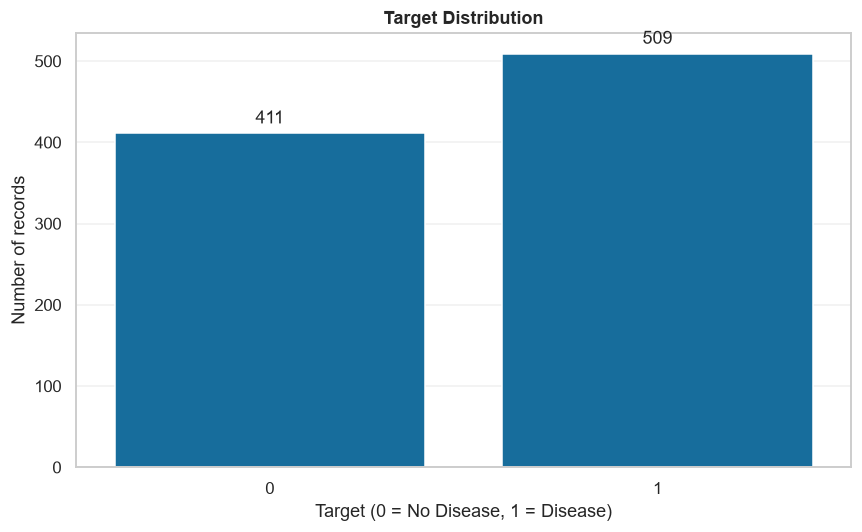

,percent
target,
0,44.67%
1,55.33%


In [24]:
target_counts = df["target"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, ax=ax)
ax.set(title="Target Distribution", xlabel="Target (0 = No Disease, 1 = Disease)", ylabel="Number of records")
ax.grid(axis="y", alpha=0.3)
for bar, count in zip(ax.patches, target_counts.values):
    ax.annotate(f"{count:,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
fig.tight_layout()
fig.savefig(figures_dir / "target_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display((target_counts / len(df) * 100).rename("percent").to_frame().style.format("{:.2f}%"))

**Insight.** The chart and percentage table show the observed class balance. Any imbalance should be considered when selecting evaluation metrics: accuracy alone can obscure minority-class performance. Preserve class proportions in train/test splits and report class-sensitive measures such as recall, precision, F1, and ROC-AUC as appropriate.

### Age Distribution

Inspect age with a histogram and a median reference line. The shape indicates whether the cohort is concentrated in particular age bands and whether a symmetric summary would be adequate.

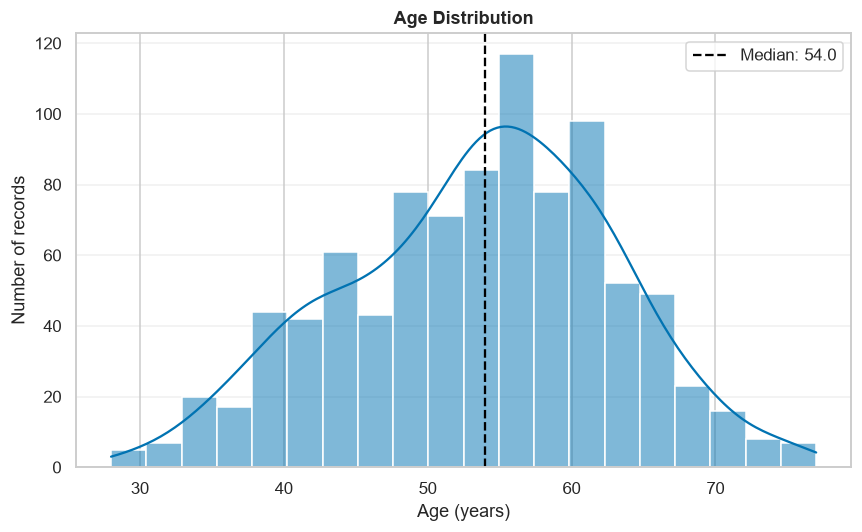

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=20, kde=True, ax=ax, color=sns.color_palette()[0])
ax.axvline(df["age"].median(), color="black", linestyle="--", label=f"Median: {df['age'].median():.1f}")
ax.set(title="Age Distribution", xlabel="Age (years)", ylabel="Number of records")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "age_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Insight.** Use the histogram to assess cohort age concentration, spread, and possible tail observations. The plotted median is a descriptive reference for this combined dataset and should not be interpreted as a population estimate without considering how the source cohorts were selected.

### Cholesterol Distribution

Visualize serum cholesterol (`chol`) while omitting missing values for this plot only. A histogram with a density estimate helps reveal skew, multiple concentrations, and extreme values that a mean alone may hide.

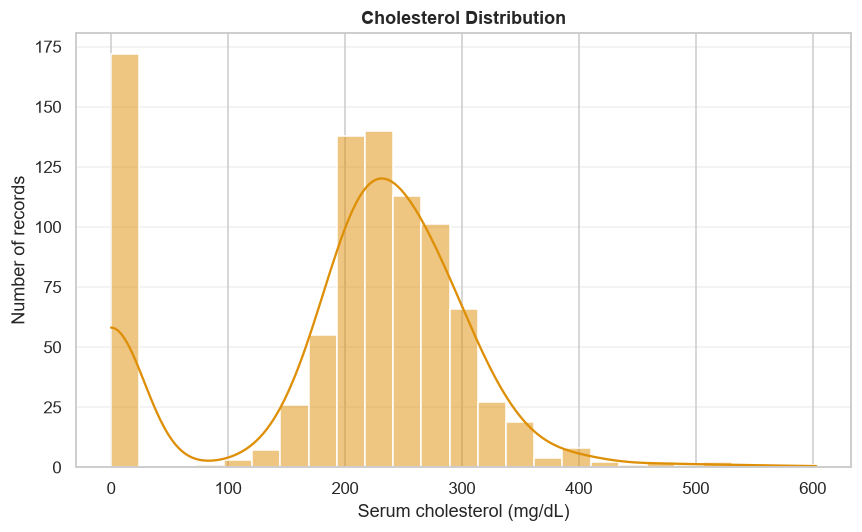

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="chol", bins=25, kde=True, ax=ax, color=sns.color_palette()[1])
ax.set(title="Cholesterol Distribution", xlabel="Serum cholesterol (mg/dL)", ylabel="Number of records")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "cholesterol_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Insight.** Evaluate the distribution for skew and unusually low or high measurements, and interpret it with the missing-value count. Apparent extremes should be investigated against source documentation before removal or transformation; unusual values can reflect cohort differences or data encoding as well as genuine measurements.

### Resting Blood Pressure Distribution

Plot resting blood pressure (`trestbps`) to inspect its central range and shape. Missing values are excluded from this single-feature visualization, not from the dataframe.

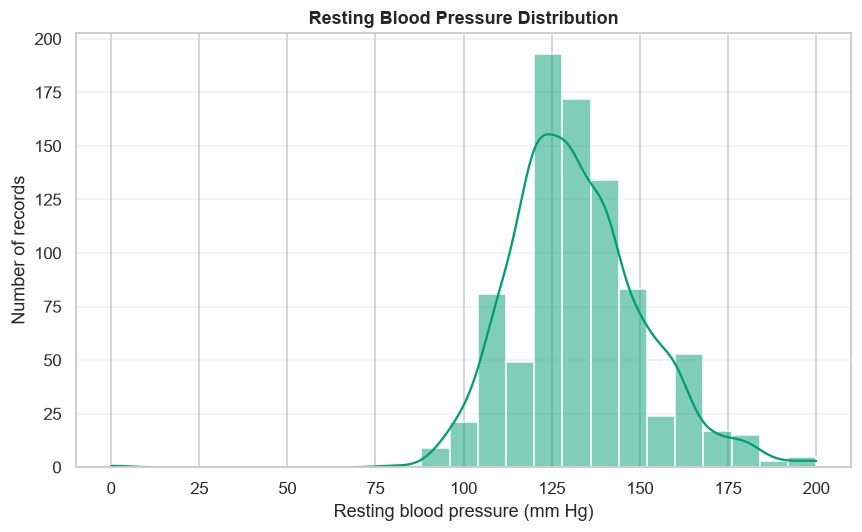

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="trestbps", bins=25, kde=True, ax=ax, color=sns.color_palette()[2])
ax.set(title="Resting Blood Pressure Distribution", xlabel="Resting blood pressure (mm Hg)", ylabel="Number of records")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "resting_bp_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Insight.** The plot shows the observed spread and possible tail values in resting blood pressure. Investigate extreme records and account for incomplete measurements during preprocessing; this visualization does not establish clinical normality or abnormality.

### Maximum Heart Rate Distribution

Examine maximum heart rate achieved (`thalach`) using a histogram and density estimate. This feature has missing observations, so its displayed sample size may be less than the full dataset.

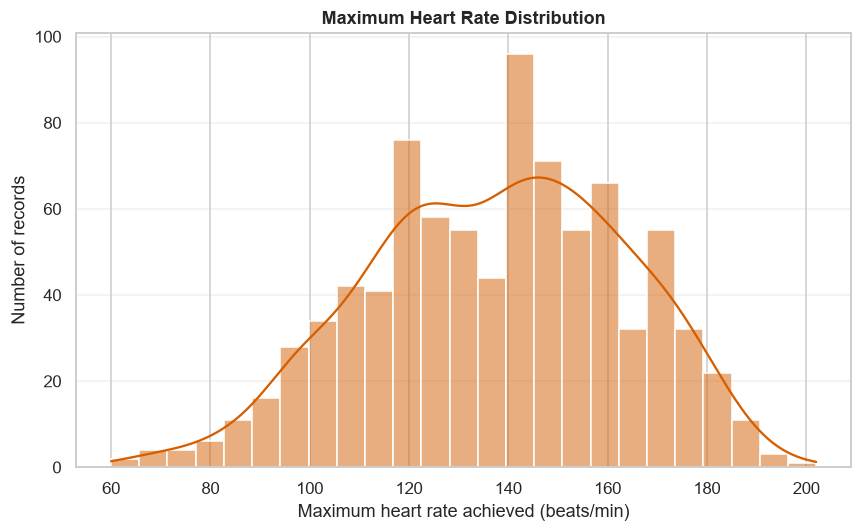

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="thalach", bins=25, kde=True, ax=ax, color=sns.color_palette()[3])
ax.set(title="Maximum Heart Rate Distribution", xlabel="Maximum heart rate achieved (beats/min)", ylabel="Number of records")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "max_heart_rate_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Insight.** Assess the distribution's center, range, and potential tail observations, keeping missingness in view. Differences in maximum heart rate may be informative in modeling, but their association with the outcome must be evaluated without implying causation.

## Bivariate Analysis

Compare selected categorical measurements and age against the binary outcome. Categorical predictors are stored as numeric codes; plot labels below clarify the known meanings without treating the codes as continuous quantities. For categorical charts, within-category outcome proportions are often easier to compare than raw counts when category sizes differ. These exploratory associations are not causal effects.

### Gender vs Heart Disease

The `sex` field is encoded as 1 for male and 0 for female in this dataset. Compare the proportion of each target class within each recorded sex category, and display category sizes to provide context.

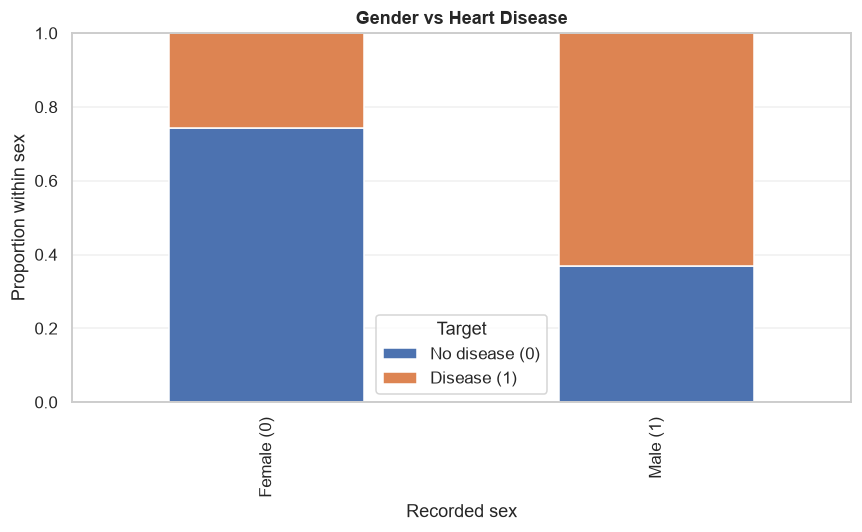

,records
Gender,
Male (1),726
Female (0),194


In [29]:
gender_data = df[["sex", "target"]].dropna().copy()
gender_data["Gender"] = gender_data["sex"].map({0: "Female (0)", 1: "Male (1)"}).fillna(gender_data["sex"].astype(str))
gender_rates = pd.crosstab(gender_data["Gender"], gender_data["target"], normalize="index").reindex(columns=[0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
gender_rates.plot(kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], ax=ax)
ax.set(title="Gender vs Heart Disease", xlabel="Recorded sex", ylabel="Proportion within sex", ylim=(0, 1))
ax.legend(title="Target", labels=["No disease (0)", "Disease (1)"])
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "gender_vs_target.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(gender_data["Gender"].value_counts().rename("records").to_frame())

**Interpretation.** Compare the disease proportions within each gender category, not only the heights of raw counts. Category sizes can affect the apparent stability of these rates. This is a pattern in the merged dataset and may reflect cohort selection or other covariates; it is not evidence that sex causes disease.

### Chest Pain Type vs Heart Disease

Compare target proportions across chest-pain-type codes (`cp`). The UCI coding is categorical; this chart deliberately treats each observed code as a separate group rather than assuming that successive codes represent equal numerical increments.

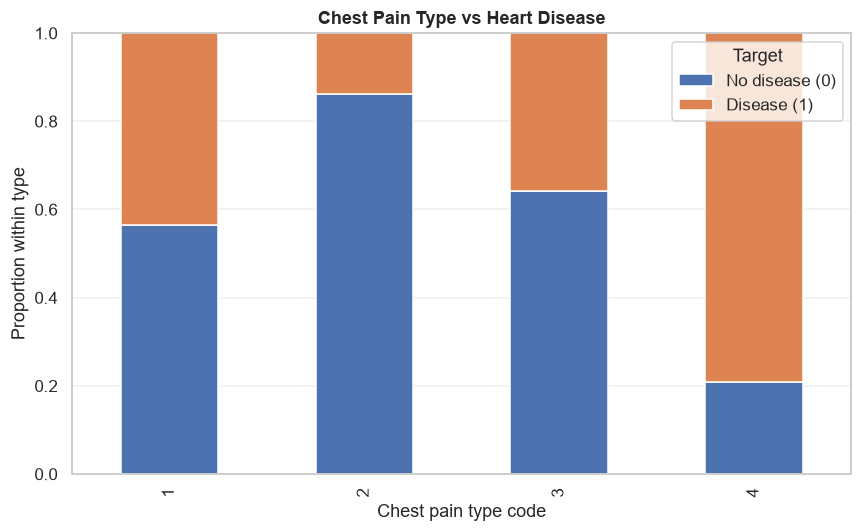

,records
cp,
1.0,46
2.0,174
3.0,204
4.0,496


In [30]:
cp_data = df[["cp", "target"]].dropna().copy()
cp_rates = pd.crosstab(cp_data["cp"].astype(int), cp_data["target"], normalize="index").reindex(columns=[0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
cp_rates.plot(kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], ax=ax)
ax.set(title="Chest Pain Type vs Heart Disease", xlabel="Chest pain type code", ylabel="Proportion within type", ylim=(0, 1))
ax.legend(title="Target", labels=["No disease (0)", "Disease (1)"])
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "chest_pain_vs_target.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(cp_data["cp"].value_counts().sort_index().rename("records").to_frame())

**Interpretation.** Differences in within-category proportions suggest chest-pain type may help distinguish outcomes in this sample. Read the accompanying category counts because small groups can produce unstable percentages. Confirm category definitions against the dataset documentation before translating codes into clinical labels.

### Exercise-Induced Angina vs Heart Disease

The `exang` feature is recorded as a binary category (0 or 1). Compare disease proportions for each observed category and show group sizes; missing records are excluded from this plot only.

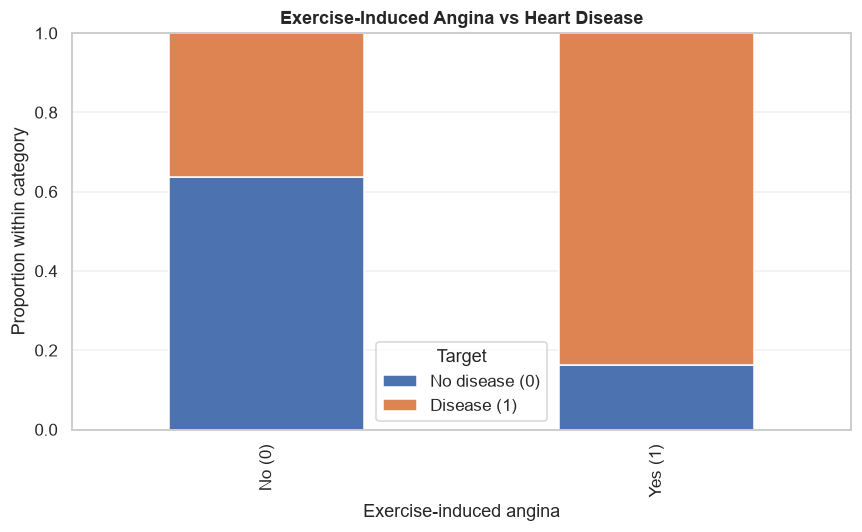

,records
Exercise-induced angina,
No (0),528
Yes (1),337


In [31]:
exang_data = df[["exang", "target"]].dropna().copy()
exang_data["Exercise-induced angina"] = exang_data["exang"].map({0: "No (0)", 1: "Yes (1)"}).fillna(exang_data["exang"].astype(str))
exang_rates = pd.crosstab(exang_data["Exercise-induced angina"], exang_data["target"], normalize="index").reindex(columns=[0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
exang_rates.plot(kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], ax=ax)
ax.set(title="Exercise-Induced Angina vs Heart Disease", xlabel="Exercise-induced angina", ylabel="Proportion within category", ylim=(0, 1))
ax.legend(title="Target", labels=["No disease (0)", "Disease (1)"])
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "exang_vs_target.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(exang_data["Exercise-induced angina"].value_counts().rename("records").to_frame())

**Interpretation.** Compare the disease proportions and sample sizes across the two exercise-induced angina categories. A visible difference is an exploratory association only; it should be assessed in validation data and in a multivariable model before drawing predictive conclusions.

### Age vs Target

Compare age distributions for records with and without heart disease using a boxplot. The box summarizes the median and interquartile range, while individual points can reveal potential outliers; missing age/target values, if any, are excluded.

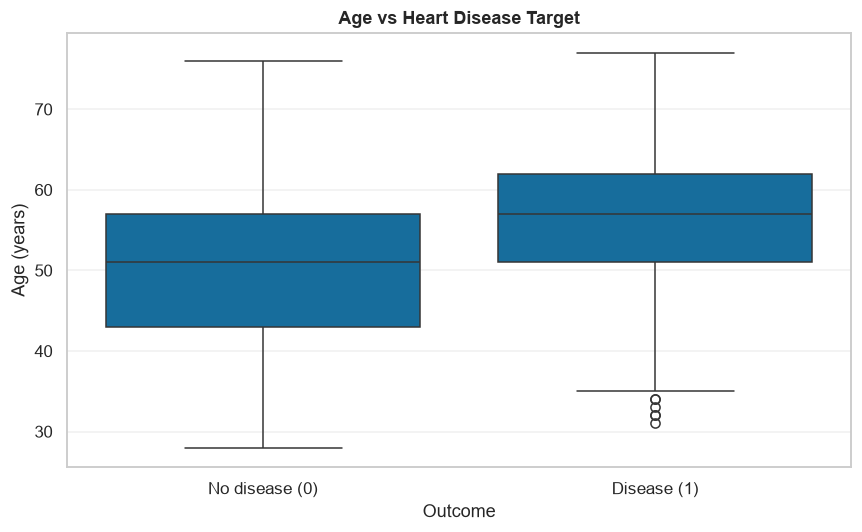

,count,mean,std,min,25%,50%,75%,max
Outcome,,,,,,,,
Disease (1),509.0,55.903733,8.718959,31.0,51.0,57.0,62.0,77.0
No disease (0),411.0,50.547445,9.433700,28.0,43.0,51.0,57.0,76.0


In [32]:
age_target = df[["age", "target"]].dropna().copy()
age_target["Outcome"] = age_target["target"].map({0: "No disease (0)", 1: "Disease (1)"})
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=age_target, x="Outcome", y="age", ax=ax)
ax.set(title="Age vs Heart Disease Target", xlabel="Outcome", ylabel="Age (years)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "age_vs_target.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(age_target.groupby("Outcome", observed=True)["age"].describe())

**Interpretation.** Compare the medians, interquartile ranges, and overlap between outcome groups. Overlapping distributions indicate that age alone does not perfectly separate outcomes. The boxplot highlights differences in this sample but does not adjust for other features or establish causality.

## Correlation Analysis

Calculate Pearson correlations for numeric columns and visualize them in an annotated heatmap. The larger figure and compact annotations support readable report exports. Correlation is a linear association measure; category codes are numeric but categorical, and missing values are handled pairwise by pandas. Use the feature-to-target ranking as an exploratory screening aid, not as a causal or final feature-importance analysis.

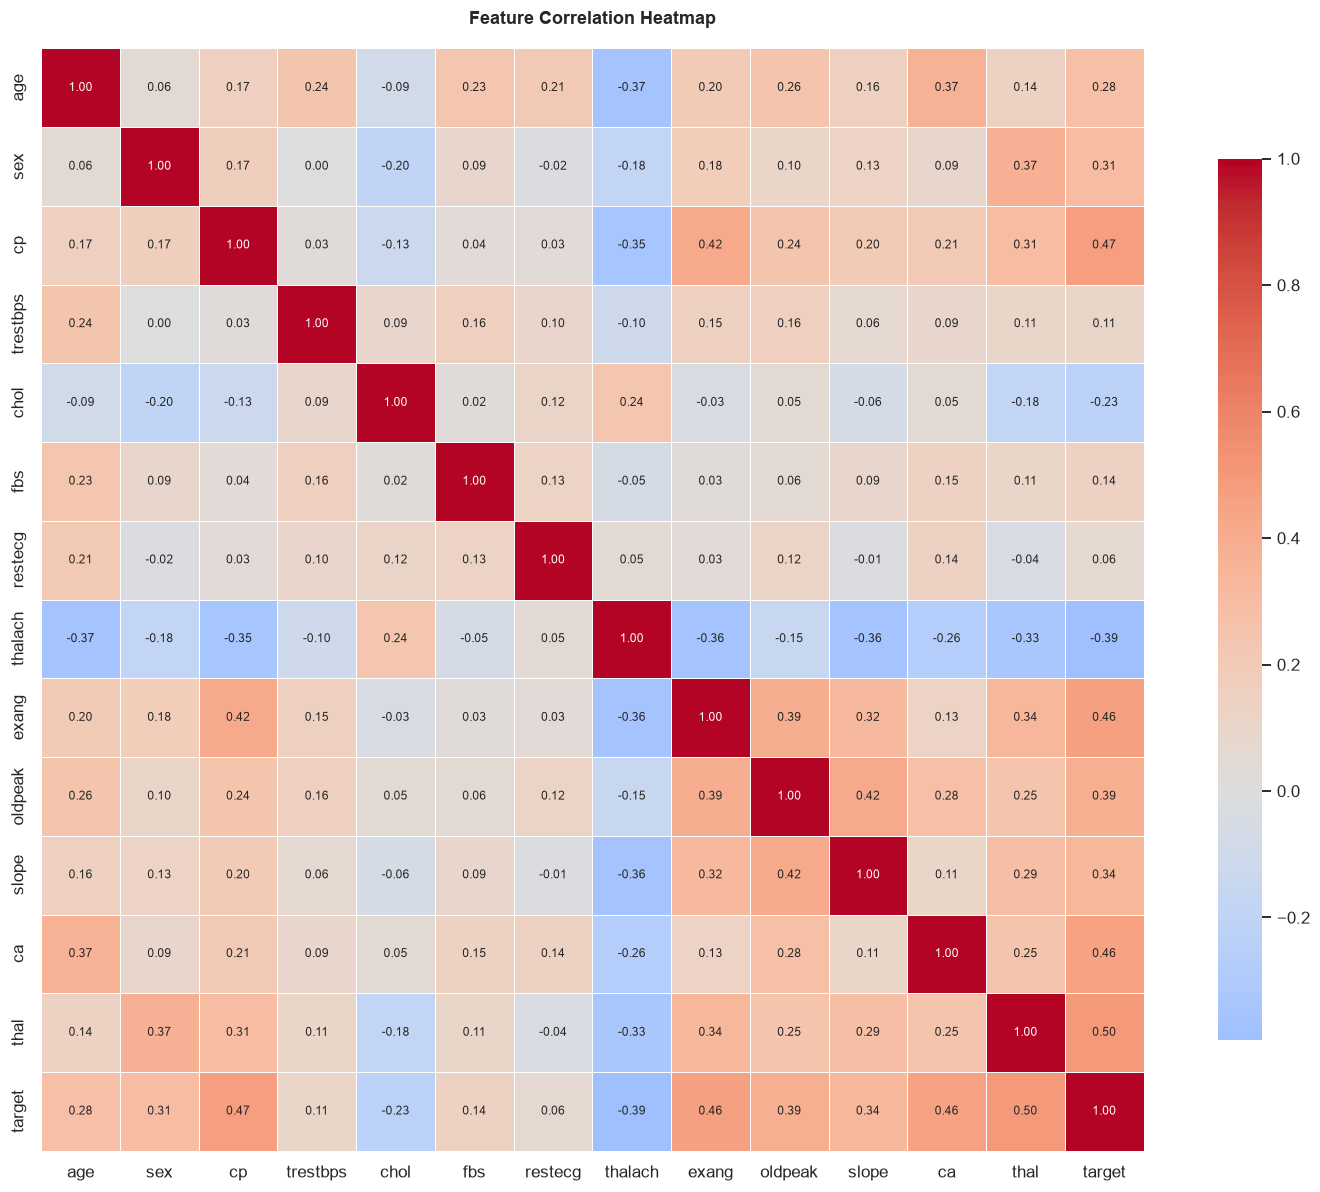

Top negatively correlated features with target:


,correlation_with_target
thalach,-0.395
chol,-0.231


Top positively correlated features with target:


,correlation_with_target
thal,0.499
cp,0.472
exang,0.464
ca,0.456
oldpeak,0.386


In [33]:
correlation = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8},
    ax=ax,
)
ax.set_title("Feature Correlation Heatmap", pad=16)
fig.tight_layout()
fig.savefig(figures_dir / "correlation_heatmap.png", bbox_inches="tight")
plt.show()
plt.close(fig)

if "target" not in correlation:
    raise KeyError("Target is unavailable for correlation analysis.")
target_correlations = correlation["target"].drop(labels="target").dropna()
top_negative = target_correlations[target_correlations < 0].nsmallest(5).rename("correlation_with_target").to_frame()
top_positive = target_correlations[target_correlations > 0].nlargest(5).rename("correlation_with_target").to_frame()
print("Top negatively correlated features with target:")
display(top_negative.style.format("{:.3f}"))
print("Top positively correlated features with target:")
display(top_positive.style.format("{:.3f}"))

**Interpretation.** Features with larger positive or negative correlations have stronger linear association with the numeric target in this merged sample. Because binary outcomes and categorical codes are represented numerically, Pearson correlation is only a first-pass summary. Correlated predictors may also carry overlapping information. Confirm useful predictors using correctly split training/validation data and an appropriate model-based analysis.

## Feature Relationships

Inspect selected relationships among age, cholesterol, resting blood pressure, maximum heart rate, and target. A pairplot can reveal broad pairwise trends, clusters, and potential outliers while coloring records by outcome. To keep the plot legible and complete-case selection explicit, the sample is limited to these five variables and records complete for all of them. This visualization is descriptive and does not replace the full-data missingness analysis.

Complete records for selected features: 834 of 920


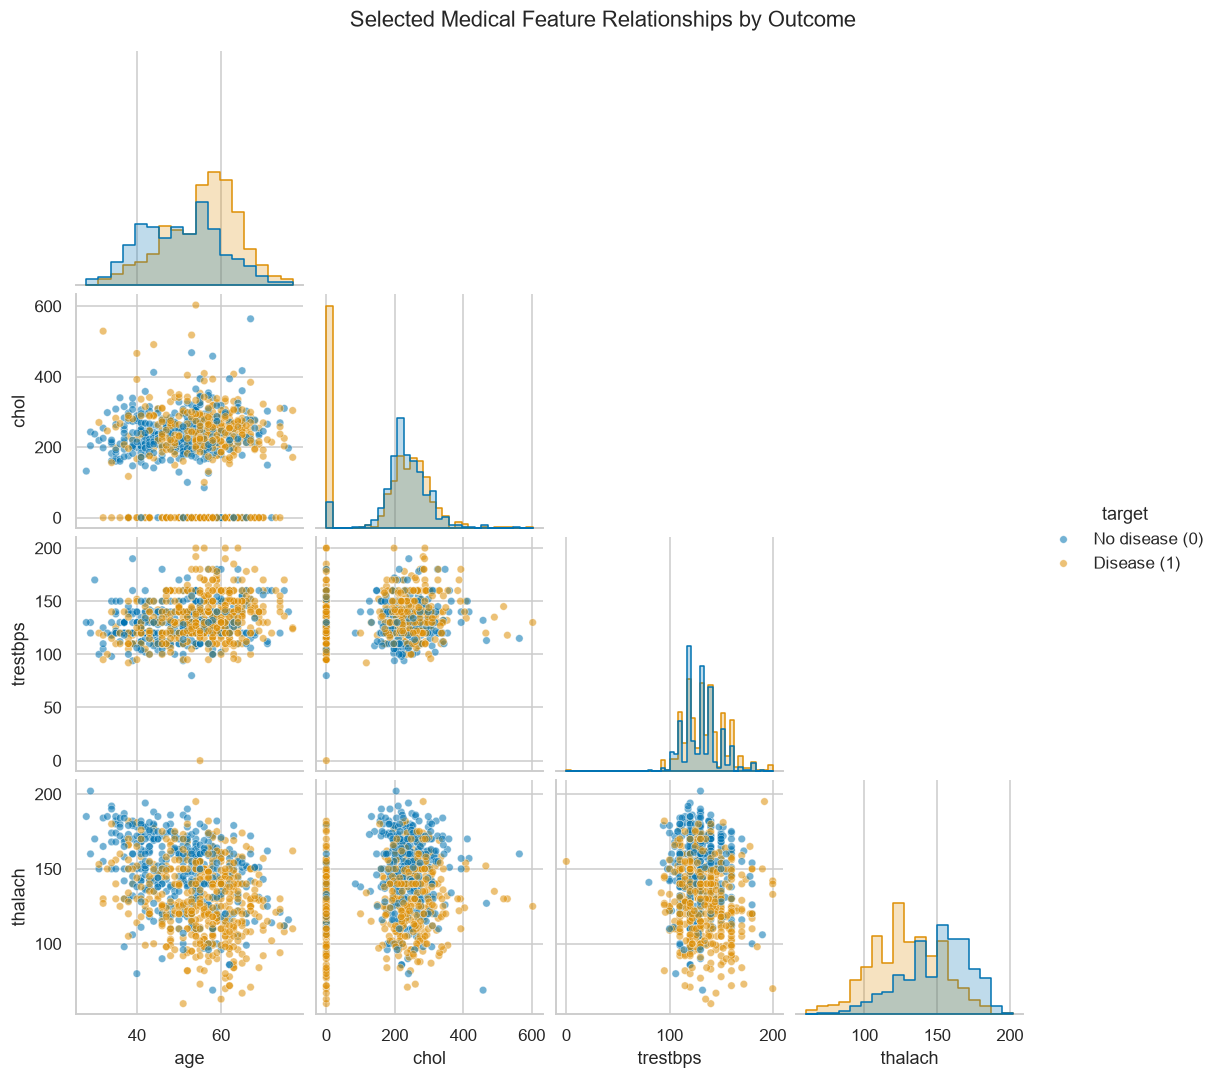

In [34]:
relationship_features = ["age", "chol", "trestbps", "thalach", "target"]
relationship_data = df[relationship_features].dropna().copy()
relationship_data["target"] = relationship_data["target"].map({0: "No disease (0)", 1: "Disease (1)"})
print(f"Complete records for selected features: {len(relationship_data):,} of {len(df):,}")
pair_plot = sns.pairplot(
    relationship_data,
    vars=["age", "chol", "trestbps", "thalach"],
    hue="target",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.55, "s": 24},
    diag_kws={"element": "step", "common_norm": False},
    height=2.4,
)
pair_plot.fig.suptitle("Selected Medical Feature Relationships by Outcome", y=1.02)
pair_plot.fig.savefig(figures_dir / "selected_feature_relationships.png", bbox_inches="tight")
plt.show()
plt.close(pair_plot.fig)

**Interpretation.** Use the pairplot to look for pairwise trends and potential overlap between outcome groups among complete records. Relationships may be nonlinear and distributions may overlap substantially. Because complete-case filtering reduces the plotted sample, its patterns may not represent records with missing values; modeling should use a deliberate missing-data strategy.

## Key Findings

The summary below derives headline figures from the loaded dataset so that the report remains consistent if the prepared CSV is regenerated. Correlation ranking is presented as a descriptive screening result only. Interpret all patterns in light of missing data, merged source cohorts, encoded categorical fields, and the observational nature of the dataset.

In [35]:
class_counts = df["target"].value_counts().reindex([0, 1], fill_value=0)
class_percentages = class_counts.div(len(df)).mul(100)
missing_total = int(df.isna().sum().sum())
duplicate_total = int(df.duplicated().sum())
feature_correlations = correlation["target"].drop(labels="target").dropna().sort_values(key=lambda values: values.abs(), ascending=False)
top_associations = feature_correlations.head(5).rename("correlation_with_target").to_frame()

print(f"Records: {len(df):,}")
print(f"Total columns: {df.shape[1]} (predictors: {df.shape[1] - 1}; target: 1)")
print(f"Class 0 — no heart disease: {class_counts.loc[0]:,} ({class_percentages.loc[0]:.2f}%)")
print(f"Class 1 — heart disease: {class_counts.loc[1]:,} ({class_percentages.loc[1]:.2f}%)")
print(f"Missing cells: {missing_total:,}; exact duplicate rows: {duplicate_total:,}")
print("Features with the largest absolute Pearson correlations with target:")
display(top_associations.style.format("{:.3f}"))

Records: 920
Total columns: 14 (predictors: 13; target: 1)
Class 0 — no heart disease: 411 (44.67%)
Class 1 — heart disease: 509 (55.33%)
Missing cells: 1,759; exact duplicate rows: 2
Features with the largest absolute Pearson correlations with target:


,correlation_with_target
thal,0.499
cp,0.472
exang,0.464
ca,0.456
thalach,-0.395


### Summary and MLOps readiness

This analysis covers the full combined cohort and the binary disease outcome. The printed summary reports the exact record count, predictor count, class balance, missing-cell and duplicate counts, and the features with the largest absolute target correlations. Review those computed values alongside the figures before incorporating them into a final report.

Notable patterns in the target, distributions, and feature relationships are useful hypotheses for model development—not claims of causation or clinical performance. Key challenges include incomplete measurements, retained duplicate records, categorical variables represented by numeric codes, potential cohort heterogeneity across the four source datasets, and possible relationships among predictors. The saved figures in `screenshots/` provide report-ready evidence of these checks.

The dataset is ready for the next stage of an MLOps workflow in the sense that it has a documented schema and an initial quality/profile assessment. Before training, define a reproducible missing-data and duplicate policy, encode categorical predictors appropriately, split data without leakage (with stratification where suitable), and evaluate using relevant metrics. Record preprocessing, data provenance, model parameters, and evaluation artifacts so that the eventual model can be reproduced and monitored. This exploratory notebook does not validate the dataset for clinical decision-making.